# Notebook 18 - Grid Search `THETA_REF` x `W_MIN` (Sample Weighting) + Training Final

**Notebook 13 TIDAK diubah.** Melanjutkan Notebook 17 (naive label + sample
weighting, HPO baru mengalahkan naive polos: F1-macro 0.541 -> 0.606).
Notebook ini mencoba **grid `THETA_REF` x `W_MIN`** - untuk TIAP kombinasi,
**Random Search dijalankan ulang dari nol** (bukan reuse config kombinasi
lain), supaya tiap titik grid punya konfigurasi yang benar-benar
dioptimalkan untuknya sendiri - baru lalu dibandingkan. Bagian akhir
melatih **model final** memakai kombinasi terbaik yang ditemukan.

```
weight_i = clip(|fwd_return_5hari_i| / THETA_REF, W_MIN, 1.0)
```

- `THETA_REF` (ambang "sinyal jelas"): **0.005 (0.5%), 0.01 (1%), 0.02 (2%)**
- `W_MIN` (bobot minimum utk sampel paling ambigu): **0.1, 0.2, 0.35**
- 3 x 3 = **9 kombinasi**, tiap kombinasi: Random Search 15 iterasi + ensemble
  6 seed final (`[2,16,25,27,32,64]`, sama dgn Notebook 13/16/17).

Data/label/split/capping/scaling/windowing dihitung **SEKALI SAJA** (tidak
tergantung `theta_ref`/`w_min`), memakai `load_return_features()` - fitur
return OHLCV + `sentiment_mean` yang SUDAH stasioner dan sudah tersedia
dari pipeline produksi (TIDAK perlu menjalankan ulang FinBERT scoring).

## Setup

In [1]:
from __future__ import annotations

import json
import logging
import sys
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("E:/forecasting_index_snp500/stock_prediction")
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)

logging.basicConfig(level=logging.INFO, format="%(asctime)s  %(levelname)-8s  %(message)s", datefmt="%H:%M:%S")
logger = logging.getLogger("notebook18")

ARTIFACT_DIR = ROOT / "data/artifacts/lstm_weights"
NAIVE_METADATA_PATH = ARTIFACT_DIR / "notebook13_fixed_metadata.json"

OUT_DIR = ROOT / "notebooks" / "outputs" / "notebook18"
OUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW = 20
HORIZON = 5
SEED = 42
ENSEMBLE_SEEDS = [2, 16, 25, 27, 32, 64]

THETA_GRID = [0.005, 0.01, 0.02]
WMIN_GRID = [0.1, 0.2, 0.35]
N_ITER_SEARCH = 15  # dikurangi dari 20 (Notebook 17) - 9 kombinasi x full search

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info("Device: %s", device)

from pipeline.feature_engineering.dataset_builder import load_return_features, RETURN_FEATURE_COLS_B
from models.lstm.notebook07_common import (
    load_split_capped, compute_class_weights, sweep_best_threshold, sample_config,
    _make_windows,
)
from models.lstm.lstm_model import FlexibleLSTMClassifier

FEATURE_COLS = RETURN_FEATURE_COLS_B
CAPPING_COLS = RETURN_FEATURE_COLS_B

with open(NAIVE_METADATA_PATH, encoding="utf-8") as f:
    naive_metadata = json.load(f)
print("Baseline naive TANPA bobot (Notebook 13):", naive_metadata["metrics"])

15:43:35  INFO      Device: cuda


Baseline naive TANPA bobot (Notebook 13): {'accuracy': 0.542857, 'precision': 0.822581, 'recall': 0.375, 'f1': 0.515152, 'f1_macro': 0.54136}


## Bagian 1 - Load Data + Label Naive + Windowing (SEKALI SAJA, Tidak Bergantung theta/w_min)

`load_return_features()` mengembalikan data yang SUDAH distasionerkan
(`ret_open/high/low/close/volume` + `sentiment_mean`) dari pipeline
produksi - TIDAK menjalankan ulang FinBERT (skor sentimen harian sudah
diregenerasi sebelumnya dan disimpan di `data/processed/sentiment/`).

In [6]:
def load_data_fn() -> pd.DataFrame:
    df = load_return_features().copy()
    df["fwd_return_h5"] = df["Close"].shift(-HORIZON) / df["Close"] - 1.0
    return df


df_train, df_val, df_test, capping_bounds, n_capped = load_split_capped(
    load_data_fn, capping_cols=CAPPING_COLS, horizon=HORIZON, train_ratio=0.70, val_ratio=0.15,
)




scaler = MinMaxScaler()
train_feat = scaler.fit_transform(df_train[FEATURE_COLS].values.astype(np.float64))
val_feat = scaler.transform(df_val[FEATURE_COLS].values.astype(np.float64))
test_feat = scaler.transform(df_test[FEATURE_COLS].values.astype(np.float64))

X_train, y_train = _make_windows(train_feat, df_train["label"].values, WINDOW)
X_val, y_val = _make_windows(val_feat, df_val["label"].values, WINDOW)
X_test, y_test = _make_windows(test_feat, df_test["label"].values, WINDOW)
y_test_arr = y_test.astype(int)


def window_align_1d(values: np.ndarray, window: int, num_samples: int) -> np.ndarray:
    return values[window - 1: window - 1 + num_samples].astype(np.float32)


fwd_return_train = window_align_1d(df_train["fwd_return_h5"].values, WINDOW, len(y_train))

print(f"X_train={X_train.shape}  X_val={X_val.shape}  X_test={X_test.shape}")

X_val_t = torch.from_numpy(X_val).to(device)
X_test_t = torch.from_numpy(X_test).to(device)
val_ds = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)  # batch_size final di-override per config saat dipakai

15:45:44  INFO      Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
15:45:44  INFO      Sentiment loaded: 1528 rows (2018-01-02 – 2024-03-04)
15:45:44  INFO      Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
15:45:44  INFO      Return-features dataset: 1526 rows (2018-01-03 – 2024-03-04)


X_train=(1045, 20, 6)  X_val=(209, 20, 6)  X_test=(210, 20, 6)


## Bagian 2 - Fungsi Reusable (Training Berbobot, Random Search, Ensemble)

In [7]:
def train_one_epoch_weighted(model, loader, optimizer, class_weights, device):
    model.train()
    ce = nn.CrossEntropyLoss(weight=class_weights, reduction="none")
    total_loss, n_samples = 0.0, 0
    y_true_all, y_pred_all = [], []
    for xb, yb, wb in loader:
        xb, yb, wb = xb.to(device), yb.to(device), wb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        per_sample_loss = ce(logits, yb)
        loss = (per_sample_loss * wb).sum() / wb.sum()
        loss.backward()
        optimizer.step()
        bs = xb.size(0)
        total_loss += loss.item() * bs
        n_samples += bs
        preds = logits.argmax(dim=1).detach().cpu().numpy()
        y_true_all.extend(yb.detach().cpu().numpy().tolist())
        y_pred_all.extend(preds.tolist())
    avg_loss = total_loss / n_samples if n_samples else 0.0
    acc = accuracy_score(y_true_all, y_pred_all) if n_samples else 0.0
    return avg_loss, float(acc)


def val_f1_macro_quick(model, X_val_t, y_val, n_steps: int = 39) -> float:
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(X_val_t), dim=1)[:, 1].cpu().numpy()
    best = -1.0
    for t in np.linspace(0.05, 0.95, n_steps):
        best = max(best, f1_score(y_val, (p >= t).astype(int), average="macro", zero_division=0))
    return float(best)


def build_optimizer_wd(name: str, params, lr: float, weight_decay: float = 0.0):
    if name == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(f"Optimizer tidak dikenal: {name}")


MIN_EPOCHS, PATIENCE = 20, 15


def train_with_early_stopping_weighted(model, train_loader, X_val_t, y_val, optimizer,
                                       class_weights, device, max_epochs: int,
                                       min_epochs: int = MIN_EPOCHS, patience: int = PATIENCE):
    best_score, best_state, epochs_no_improve, stopped_epoch = -1.0, None, 0, max_epochs
    train_losses = []
    for epoch in range(1, max_epochs + 1):
        train_loss, _ = train_one_epoch_weighted(model, train_loader, optimizer, class_weights, device)
        val_f1m = val_f1_macro_quick(model, X_val_t, y_val)
        train_losses.append(train_loss)
        if val_f1m > best_score + 1e-5:
            best_score, epochs_no_improve = val_f1m, 0
            best_state = deepcopy({k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        else:
            if epoch >= min_epochs:
                epochs_no_improve += 1
            if epoch >= min_epochs and epochs_no_improve >= patience:
                stopped_epoch = epoch
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return train_losses, stopped_epoch


SEARCH_SPACE_FIXED = {
    "hidden_size": [16, 32, 64], "num_layers": [1, 2], "dropout": (0.0, 0.3),
    "optimizer": ["adam", "rmsprop"], "activation": ["relu", "tanh"],
    "lr": (5e-4, 5e-3), "epochs": [150], "batch_size": [32, 64],
}
WEIGHT_DECAY_CHOICES = [0.0, 1e-5]


def run_grid_point(theta_ref: float, w_min: float, n_iter: int, seeds: list[int]) -> tuple[dict, list[dict]]:
    w_train = np.clip(np.abs(fwd_return_train) / theta_ref, w_min, 1.0).astype(np.float32)
    train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train), torch.from_numpy(w_train))

    rng = np.random.default_rng(SEED)
    best = {"val_f1_macro": -1.0, "config": None}
    n_collapse = 0
    collapse_ref = f1_score(y_val, np.ones_like(y_val), average="macro", zero_division=0)
    iter_history = []

    for i in range(n_iter):
        config_i = sample_config(rng, SEARCH_SPACE_FIXED)
        config_i["weight_decay"] = float(rng.choice(WEIGHT_DECAY_CHOICES))
        torch.manual_seed(SEED + i)
        model_i = FlexibleLSTMClassifier(
            input_size=len(FEATURE_COLS), hidden_size=config_i["hidden_size"],
            num_layers=config_i["num_layers"], dropout=config_i["dropout"],
            activation=config_i["activation"], num_classes=2,
        ).to(device)
        optimizer_i = build_optimizer_wd(config_i["optimizer"], model_i.parameters(), config_i["lr"], config_i["weight_decay"])
        class_weights_i = compute_class_weights(y_train, device)
        train_loader_i = DataLoader(train_ds, batch_size=config_i["batch_size"], shuffle=True)

        _, stopped_epoch_i = train_with_early_stopping_weighted(
            model_i, train_loader_i, X_val_t, y_val, optimizer_i, class_weights_i, device,
            max_epochs=config_i["epochs"],
        )
        model_i.eval()
        with torch.no_grad():
            val_probs_i = torch.softmax(model_i(X_val_t), dim=1)[:, 1].cpu().numpy()
        _, val_f1_macro_i = sweep_best_threshold(y_val, val_probs_i)
        is_collapse_i = abs(val_f1_macro_i - collapse_ref) < 1e-3
        if is_collapse_i:
            n_collapse += 1
        is_new_best_i = val_f1_macro_i > best["val_f1_macro"]
        if is_new_best_i:
            best = {"val_f1_macro": val_f1_macro_i, "config": config_i}

        iter_history.append({
            "theta_ref": theta_ref, "w_min": w_min, "iteration": i + 1,
            **config_i, "val_f1_macro": val_f1_macro_i,
            "stopped_epoch": stopped_epoch_i, "is_collapse": is_collapse_i, "is_new_best": is_new_best_i,
        })

    best_config = best["config"]
    models = []
    for seed in seeds:
        torch.manual_seed(seed)
        model_s = FlexibleLSTMClassifier(
            input_size=len(FEATURE_COLS), hidden_size=best_config["hidden_size"],
            num_layers=best_config["num_layers"], dropout=best_config["dropout"],
            activation=best_config["activation"], num_classes=2,
        ).to(device)
        optimizer_s = build_optimizer_wd(best_config["optimizer"], model_s.parameters(), best_config["lr"], best_config["weight_decay"])
        class_weights_s = compute_class_weights(y_train, device)
        train_loader_s = DataLoader(train_ds, batch_size=best_config["batch_size"], shuffle=True)
        train_with_early_stopping_weighted(
            model_s, train_loader_s, X_val_t, y_val, optimizer_s, class_weights_s, device,
            max_epochs=best_config["epochs"],
        )
        models.append(model_s)

    with torch.no_grad():
        ens_val_probs = np.mean([torch.softmax(m(X_val_t), dim=1)[:, 1].cpu().numpy() for m in models], axis=0)
        ens_test_probs = np.mean([torch.softmax(m(X_test_t), dim=1)[:, 1].cpu().numpy() for m in models], axis=0)
    threshold, _ = sweep_best_threshold(y_val, ens_val_probs)
    y_test_pred = (ens_test_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_arr, y_test_pred, labels=[0, 1]).ravel()

    metrics = {
        "accuracy": accuracy_score(y_test_arr, y_test_pred),
        "precision": precision_score(y_test_arr, y_test_pred, zero_division=0),
        "recall": recall_score(y_test_arr, y_test_pred, zero_division=0),
        "f1": f1_score(y_test_arr, y_test_pred, zero_division=0),
        "f1_macro": f1_score(y_test_arr, y_test_pred, average="macro", zero_division=0),
        "auc_test": roc_auc_score(y_test_arr, ens_test_probs) if len(set(y_test_arr)) > 1 else float("nan"),
        "bal_acc_test": balanced_accuracy_score(y_test_arr, y_test_pred),
        "std_prob_up": float(ens_test_probs.std()),
    }
    collapse = bool(tn == 0 or tp == 0 or metrics["std_prob_up"] < 0.02)
    result = {
        "theta_ref": theta_ref, "w_min": w_min, "best_config": best_config,
        "n_collapse_search": n_collapse, "n_iter_search": n_iter,
        **metrics, "confusion_tn_fp_fn_tp": f"{tn}/{fp}/{fn}/{tp}", "collapse": collapse,
    }
    return result, iter_history

## Bagian 3 - Jalankan Grid 3x3 (9 Kombinasi, Full Random Search per Titik)

In [8]:
grid_results = []
all_iter_history = []
for theta_ref in THETA_GRID:
    for w_min in WMIN_GRID:
        logger.info("=== Grid point: theta_ref=%.3f  w_min=%.2f ===", theta_ref, w_min)
        result, iter_history = run_grid_point(theta_ref, w_min, N_ITER_SEARCH, ENSEMBLE_SEEDS)
        grid_results.append(result)
        all_iter_history.extend(iter_history)
        logger.info("  -> f1_macro=%.4f  auc=%.4f  bal_acc=%.4f  collapse=%s  n_collapse_search=%d/%d",
                    result["f1_macro"], result["auc_test"], result["bal_acc_test"],
                    result["collapse"], result["n_collapse_search"], N_ITER_SEARCH)

df_grid = pd.DataFrame(grid_results)
grid_path = OUT_DIR / "grid_search_results.csv"
df_grid.to_csv(grid_path, index=False)
print(f"Disimpan ke: {grid_path}")

df_iter_history = pd.DataFrame(all_iter_history)
history_path = OUT_DIR / "grid_search_full_iteration_history.csv"
df_iter_history.to_csv(history_path, index=False)
print(f"Riwayat LENGKAP tiap iterasi ({len(df_iter_history)} baris = {len(THETA_GRID)*len(WMIN_GRID)} titik grid x {N_ITER_SEARCH} iterasi) disimpan ke: {history_path}")

df_grid[["theta_ref", "w_min", "accuracy", "f1_macro", "auc_test", "bal_acc_test", "collapse", "n_collapse_search"]].sort_values("f1_macro", ascending=False)

15:46:39  INFO      === Grid point: theta_ref=0.005  w_min=0.10 ===
15:48:58  INFO        -> f1_macro=0.6014  auc=0.6430  bal_acc=0.6215  collapse=False  n_collapse_search=0/15
15:48:58  INFO      === Grid point: theta_ref=0.005  w_min=0.20 ===
15:50:59  INFO        -> f1_macro=0.6163  auc=0.6478  bal_acc=0.6171  collapse=False  n_collapse_search=0/15
15:50:59  INFO      === Grid point: theta_ref=0.005  w_min=0.35 ===
15:53:30  INFO        -> f1_macro=0.5306  auc=0.5892  bal_acc=0.5596  collapse=False  n_collapse_search=1/15
15:53:30  INFO      === Grid point: theta_ref=0.010  w_min=0.10 ===
15:55:33  INFO        -> f1_macro=0.5901  auc=0.6746  bal_acc=0.5944  collapse=False  n_collapse_search=1/15
15:55:33  INFO      === Grid point: theta_ref=0.010  w_min=0.20 ===
15:58:15  INFO        -> f1_macro=0.5107  auc=0.6249  bal_acc=0.5911  collapse=False  n_collapse_search=1/15
15:58:15  INFO      === Grid point: theta_ref=0.010  w_min=0.35 ===
16:00:55  INFO        -> f1_macro=0.5605  auc=0

Disimpan ke: E:\forecasting_index_snp500\stock_prediction\notebooks\outputs\notebook18\grid_search_results.csv
Riwayat LENGKAP tiap iterasi (135 baris = 9 titik grid x 15 iterasi) disimpan ke: E:\forecasting_index_snp500\stock_prediction\notebooks\outputs\notebook18\grid_search_full_iteration_history.csv


,theta_ref,w_min,accuracy,f1_macro,auc_test,bal_acc_test,collapse,n_collapse_search
1,0.005,0.20,0.647619,0.616296,0.647754,0.617051,False,0
8,0.020,0.35,0.647619,0.606343,0.637321,0.604730,False,1
0,0.005,0.10,0.609524,0.601389,0.642985,0.621522,False,0
3,0.010,0.10,0.614286,0.590111,0.674583,0.594396,False,1
5,0.010,0.35,0.561905,0.560470,0.609300,0.597079,False,0
2,0.005,0.35,0.533333,0.530609,0.589229,0.559618,False,1
4,0.010,0.20,0.514286,0.510691,0.624901,0.591117,False,1
7,0.020,0.20,0.495238,0.495238,0.573033,0.542528,False,0
6,0.020,0.10,0.433333,0.420710,0.511029,0.522456,False,2


## Bagian 4 - Heatmap Trade-off + Perbandingan vs Baseline

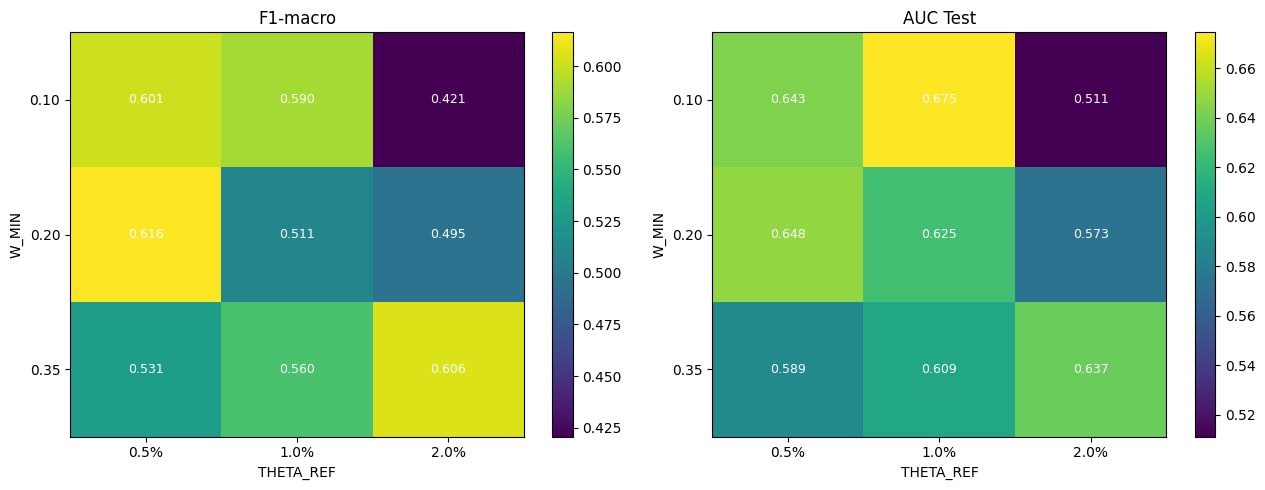

Baseline naive TANPA bobot : f1_macro=0.5414  auc=0.6450  bal_acc=0.6132
Kombinasi terbaik (F1-macro tertinggi): theta_ref=0.005  w_min=0.20
  f1_macro=0.6163  auc=0.6478  bal_acc=0.6171  collapse=False
5/9 kombinasi mengalahkan F1-macro naive TANPA bobot (0.5414)
9/9 kombinasi TIDAK collapse


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, title in [(axes[0], "f1_macro", "F1-macro"), (axes[1], "auc_test", "AUC Test")]:
    pivot = df_grid.pivot(index="w_min", columns="theta_ref", values=metric)
    im = ax.imshow(pivot.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([f"{c:.1%}" for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([f"{r:.2f}" for r in pivot.index])
    ax.set_xlabel("THETA_REF")
    ax.set_ylabel("W_MIN")
    ax.set_title(title)
    for yi in range(pivot.shape[0]):
        for xi in range(pivot.shape[1]):
            ax.text(xi, yi, f"{pivot.values[yi, xi]:.3f}", ha="center", va="center", color="white", fontsize=9)
    fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUT_DIR / "grid_heatmap.png", dpi=120)
plt.show()

naive_metrics, naive_diag = naive_metadata["metrics"], naive_metadata["diagnostics"]
print(f"Baseline naive TANPA bobot : f1_macro={naive_metrics['f1_macro']:.4f}  auc={naive_diag['auc_test']:.4f}  bal_acc={naive_diag['bal_acc_test']:.4f}")

best_row = df_grid.loc[df_grid["f1_macro"].idxmax()]
print(f"Kombinasi terbaik (F1-macro tertinggi): theta_ref={best_row['theta_ref']:.3f}  w_min={best_row['w_min']:.2f}")
print(f"  f1_macro={best_row['f1_macro']:.4f}  auc={best_row['auc_test']:.4f}  bal_acc={best_row['bal_acc_test']:.4f}  collapse={best_row['collapse']}")

n_beat_naive = (df_grid["f1_macro"] > naive_metrics["f1_macro"]).sum()
print(f"{n_beat_naive}/{len(df_grid)} kombinasi mengalahkan F1-macro naive TANPA bobot ({naive_metrics['f1_macro']:.4f})")
print(f"{(~df_grid['collapse']).sum()}/{len(df_grid)} kombinasi TIDAK collapse")

## Bagian 4.5 - Analisis: Apakah `num_layers=2` Benar-Benar Kalah, atau Cuma Kebetulan?

Riwayat LENGKAP semua percobaan (9 titik grid x 15 iterasi = 135 percobaan)
dianalisis: distribusi `num_layers` yang di-SAMPLE (bukan cuma yang MENANG),
rata-rata `val_f1_macro` per nilai `num_layers` (uji beda kasar), dan
persentase kemenangan (`is_new_best`) per nilai `num_layers`.

Total percobaan: 135

Distribusi num_layers yang DI-SAMPLE (seharusnya ~50/50 kalau murni acak):
num_layers
1    81
2    54
Name: count, dtype: int64
proporsi: {1: 60.0, 2: 40.0}

Rata-rata val_f1_macro per num_layers (SEMUA percobaan, bukan cuma pemenang):
              mean     std  count
num_layers                       
1           0.5701  0.0337     81
2           0.5281  0.0776     54

Persentase menjadi PEMENANG (is_new_best) per num_layers:
            sum  count  win_rate_%
num_layers                        
1            17     81        21.0
2             7     54        13.0

Tingkat collapse (is_collapse) per num_layers:
num_layers
1    0.0000
2    0.1111
Name: is_collapse, dtype: float64

Uji-t (val_f1_macro num_layers=1 vs num_layers=2): t=3.746  p=0.0004
-> Beda SIGNIFIKAN secara statistik - num_layers=1 punya keunggulan nyata di data ini.


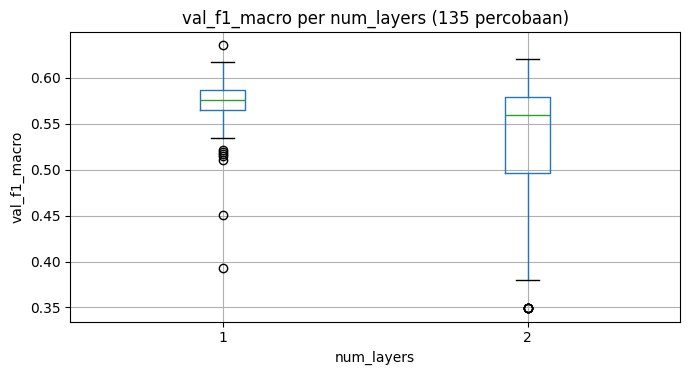

In [10]:
print(f"Total percobaan: {len(df_iter_history)}")
print("\nDistribusi num_layers yang DI-SAMPLE (seharusnya ~50/50 kalau murni acak):")
print(df_iter_history["num_layers"].value_counts())
print(f"proporsi: {(df_iter_history['num_layers'].value_counts(normalize=True) * 100).round(1).to_dict()}")

print("\nRata-rata val_f1_macro per num_layers (SEMUA percobaan, bukan cuma pemenang):")
print(df_iter_history.groupby("num_layers")["val_f1_macro"].agg(["mean", "std", "count"]).round(4))

print("\nPersentase menjadi PEMENANG (is_new_best) per num_layers:")
win_rate = df_iter_history.groupby("num_layers")["is_new_best"].agg(["sum", "count"])
win_rate["win_rate_%"] = (win_rate["sum"] / win_rate["count"] * 100).round(1)
print(win_rate)

print("\nTingkat collapse (is_collapse) per num_layers:")
print(df_iter_history.groupby("num_layers")["is_collapse"].mean().round(4))

from scipy import stats
g1 = df_iter_history.loc[df_iter_history["num_layers"] == 1, "val_f1_macro"]
g2 = df_iter_history.loc[df_iter_history["num_layers"] == 2, "val_f1_macro"]
t_stat, p_val = stats.ttest_ind(g1, g2, equal_var=False)
print(f"\nUji-t (val_f1_macro num_layers=1 vs num_layers=2): t={t_stat:.3f}  p={p_val:.4f}")
if p_val < 0.05:
    print("-> Beda SIGNIFIKAN secara statistik - num_layers=1 punya keunggulan nyata di data ini.")
else:
    print("-> Beda TIDAK signifikan (p>=0.05) - selisih menang/kalah kemungkinan besar cuma variansi sampel kecil.")

fig, ax = plt.subplots(figsize=(7, 4))
df_iter_history.boxplot(column="val_f1_macro", by="num_layers", ax=ax)
ax.set_title("val_f1_macro per num_layers (135 percobaan)")
ax.set_xlabel("num_layers")
ax.set_ylabel("val_f1_macro")
plt.suptitle("")
fig.tight_layout()
fig.savefig(OUT_DIR / "num_layers_analysis.png", dpi=120)
plt.show()

## Bagian 5 - Training Final: Kombinasi Terbaik (`theta_ref=0.5%`, `w_min=0.20`)

Kombinasi dengan F1-macro tertinggi di grid (0.616, vs naive 0.541).
Dilatih ULANG di sini sebagai model final (bukan model sisa iterasi
Random Search) - reuse `X_train/y_train/X_val/y_val/X_test/y_test` dari
Bagian 1 (data OHLCV-return + `sentiment_mean` yang SUDAH stasioner, TIDAK
menjalankan ulang FinBERT) dan `best_config` yang ditemukan grid search
untuk kombinasi ini, dibaca dari `grid_search_results.csv` (bukan
di-hardcode) supaya konsisten dengan hasil aktual.

**Ini tahap PERSIAPAN** - model + metadata disimpan ke
`notebooks/outputs/notebook18/artifacts/` (folder eksperimen ini, BUKAN
`data/artifacts/lstm_weights/` produksi) - menunggu instruksi langkah
berikutnya sebelum dipakai lebih lanjut.

In [13]:
import ast

THETA_REF_FINAL = 0.005
W_MIN_FINAL = 0.20

best_row_final = df_grid[(df_grid["theta_ref"] == THETA_REF_FINAL) & (df_grid["w_min"] == W_MIN_FINAL)].iloc[0]
best_config_final = best_row_final["best_config"]
if isinstance(best_config_final, str):  # jika df_grid dibaca ulang dari CSV, dict tersimpan sbg string
    best_config_final = ast.literal_eval(best_config_final)

print(f"Kombinasi final : theta_ref={THETA_REF_FINAL}  w_min={W_MIN_FINAL}")
print("best_config     :")
for k, v in best_config_final.items():
    print(f"  {k:14s}: {v}")

w_train_final = np.clip(np.abs(fwd_return_train) / THETA_REF_FINAL, W_MIN_FINAL, 1.0).astype(np.float32)
train_ds_final = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train), torch.from_numpy(w_train_final))

final_models = []
final_seed_rows = []
for seed in ENSEMBLE_SEEDS:
    torch.manual_seed(seed)
    model_s = FlexibleLSTMClassifier(
        input_size=len(FEATURE_COLS), hidden_size=best_config_final["hidden_size"],
        num_layers=best_config_final["num_layers"], dropout=best_config_final["dropout"],
        activation=best_config_final["activation"], num_classes=2,
    ).to(device)
    optimizer_s = build_optimizer_wd(best_config_final["optimizer"], model_s.parameters(),
                                      best_config_final["lr"], best_config_final["weight_decay"])
    class_weights_s = compute_class_weights(y_train, device)
    train_loader_s = DataLoader(train_ds_final, batch_size=best_config_final["batch_size"], shuffle=True)

    train_losses_s, stopped_epoch_s = train_with_early_stopping_weighted(
        model_s, train_loader_s, X_val_t, y_val, optimizer_s, class_weights_s, device,
        max_epochs=best_config_final["epochs"],
    )
    final_models.append(model_s)
    final_seed_rows.append({"seed": seed, "stopped_epoch": stopped_epoch_s, "min_train_loss": float(min(train_losses_s))})
    logger.info("[FINAL seed=%d] stop epoch %d, min_train_loss=%.4f", seed, stopped_epoch_s, final_seed_rows[-1]["min_train_loss"])

pd.DataFrame(final_seed_rows)

Kombinasi final : theta_ref=0.005  w_min=0.2
best_config     :
  hidden_size   : 32
  num_layers    : 1
  dropout       : 0.16957083194435665
  optimizer     : adam
  activation    : tanh
  lr            : 0.002330091449155189
  epochs        : 150
  batch_size    : 64
  weight_decay  : 1e-05


16:21:05  INFO      [FINAL seed=2] stop epoch 46, min_train_loss=0.6141
16:21:10  INFO      [FINAL seed=16] stop epoch 47, min_train_loss=0.5952
16:21:27  INFO      [FINAL seed=25] stop epoch 67, min_train_loss=0.5726
16:21:44  INFO      [FINAL seed=27] stop epoch 57, min_train_loss=0.5883
16:21:59  INFO      [FINAL seed=32] stop epoch 57, min_train_loss=0.5791
16:22:08  INFO      [FINAL seed=64] stop epoch 34, min_train_loss=0.6099


,seed,stopped_epoch,min_train_loss
0,2,46,0.614081
1,16,47,0.595237
2,25,67,0.572589
3,27,57,0.588280
4,32,57,0.579069
5,64,34,0.609869


### Evaluasi Model Final (Ensemble 6 Seed) + Simpan Artefak

In [14]:
with torch.no_grad():
    final_val_probs = np.mean([torch.softmax(m(X_val_t), dim=1)[:, 1].cpu().numpy() for m in final_models], axis=0)
    final_test_probs = np.mean([torch.softmax(m(X_test_t), dim=1)[:, 1].cpu().numpy() for m in final_models], axis=0)

final_threshold, final_val_f1_macro = sweep_best_threshold(y_val, final_val_probs)
y_test_pred_final = (final_test_probs >= final_threshold).astype(int)
tn_f, fp_f, fn_f, tp_f = confusion_matrix(y_test_arr, y_test_pred_final, labels=[0, 1]).ravel()

final_metrics = {
    "accuracy": accuracy_score(y_test_arr, y_test_pred_final),
    "precision": precision_score(y_test_arr, y_test_pred_final, zero_division=0),
    "recall": recall_score(y_test_arr, y_test_pred_final, zero_division=0),
    "f1": f1_score(y_test_arr, y_test_pred_final, zero_division=0),
    "f1_macro": f1_score(y_test_arr, y_test_pred_final, average="macro", zero_division=0),
}
final_diagnostics = {
    "auc_test": roc_auc_score(y_test_arr, final_test_probs) if len(set(y_test_arr)) > 1 else float("nan"),
    "bal_acc_test": balanced_accuracy_score(y_test_arr, y_test_pred_final),
    "std_prob_up": float(final_test_probs.std()),
    "min_train_loss": float(min(r["min_train_loss"] for r in final_seed_rows)),
}
final_collapse = bool(tn_f == 0 or tp_f == 0 or final_diagnostics["std_prob_up"] < 0.02)

print("=== Model Final (theta_ref=0.5%, w_min=0.20, ensemble 6 seed) ===")
print(f"threshold (dari val, ensemble): {final_threshold:.3f}")
for k, v in final_metrics.items():
    print(f"  {k:10s}: {v:.4f}")
print("Diagnostik:")
for k, v in final_diagnostics.items():
    print(f"  {k:14s}: {v:.4f}")
print("Confusion matrix:", {"tn": int(tn_f), "fp": int(fp_f), "fn": int(fn_f), "tp": int(tp_f)})
print("Collapse:", final_collapse)

# --- Simpan artefak (folder eksperimen notebook 18, BUKAN production ARTIFACT_DIR) ---
ARTIFACT_DIR_NB18 = OUT_DIR / "artifacts"
ARTIFACT_DIR_NB18.mkdir(parents=True, exist_ok=True)

import joblib
for seed, model_s in zip(ENSEMBLE_SEEDS, final_models):
    torch.save(model_s.state_dict(), ARTIFACT_DIR_NB18 / f"seed_{seed}_model.pt")
joblib.dump(scaler, ARTIFACT_DIR_NB18 / "scaler.joblib")

final_metadata = {
    "config": best_config_final,
    "feature_cols": FEATURE_COLS,
    "window": WINDOW,
    "horizon": HORIZON,
    "label_scheme": "naive (Close[t+H] > Close[t]) + sample weighting",
    "sample_weighting": {"theta_ref": THETA_REF_FINAL, "w_min": W_MIN_FINAL},
    "metrics": final_metrics,
    "diagnostics": final_diagnostics,
    "confusion_matrix": {"tn": int(tn_f), "fp": int(fp_f), "fn": int(fn_f), "tp": int(tp_f)},
    "threshold": float(final_threshold),
    "model_type": "ensemble_mean_probability",
    "ensemble_seeds": ENSEMBLE_SEEDS,
    "split_sizes": {
        "train_rows": len(df_train), "val_rows": len(df_val), "test_rows": len(df_test),
        "train_samples": len(X_train), "val_samples": len(X_val), "test_samples": len(X_test),
    },
    "source": "notebook18 (grid search theta_ref/w_min -> kombinasi terbaik -> training final)",
    "note": "DISIMPAN DI notebooks/outputs/notebook18/artifacts/ - BUKAN artefak produksi. Menunggu instruksi langkah berikutnya sebelum dipakai/dipindah ke produksi.",
}
metadata_path = ARTIFACT_DIR_NB18 / "final_metadata.json"
metadata_path.write_text(json.dumps(final_metadata, indent=2), encoding="utf-8")
print(f"\nModel (6 seed state_dict) + scaler + metadata disimpan ke: {ARTIFACT_DIR_NB18}")

=== Model Final (theta_ref=0.5%, w_min=0.20, ensemble 6 seed) ===
threshold (dari val, ensemble): 0.455
  accuracy  : 0.6476
  precision : 0.7313
  recall    : 0.7206
  f1        : 0.7259
  f1_macro  : 0.6163
Diagnostik:
  auc_test      : 0.6478
  bal_acc_test  : 0.6171
  std_prob_up   : 0.1016
  min_train_loss: 0.5726
Confusion matrix: {'tn': 38, 'fp': 36, 'fn': 38, 'tp': 98}
Collapse: False

Model (6 seed state_dict) + scaler + metadata disimpan ke: E:\forecasting_index_snp500\stock_prediction\notebooks\outputs\notebook18\artifacts


## Penutup

9 kombinasi `theta_ref`/`w_min` masing-masing melalui Random Search penuh
(bukan reuse config) supaya perbandingan adil. Model final (kombinasi
terbaik: `theta_ref=0.5%`, `w_min=0.20`) sudah dilatih ulang dan
disiapkan (state_dict 6 seed + scaler + metadata) di
`notebooks/outputs/notebook18/artifacts/` - siap dipakai untuk langkah
berikutnya begitu diinstruksikan. Notebook 13 TIDAK diubah oleh notebook
ini.